<a href="https://colab.research.google.com/github/laksamanaap/244107020021-machine-leaning-course-2026-/blob/main/JS10/JS10_Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Import


In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models


I0000 00:00:1794481547.138940  514352 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794481548.133530  514352 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Load dataset


In [ ]:
# ambil gambar + label dari folder
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "images/training/"
test_dir  = "images/test/"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print("train:", len(train_img), "test:", len(test_img))


train: 240 test: 160


## Pra pengolahan


In [ ]:
# resize gambar, label jadi angka
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)


## Ekstraksi fitur HOG


In [ ]:
# ekstrak fitur HOG
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

print("shape train:", X_train_feat.shape, "test:", X_test_feat.shape)


shape train: (240, 34596) test: (160, 34596)


## Standardisasi dan split validasi


In [ ]:
# standardisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

# label jadi numpy array
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)


## Buat model ANN


In [ ]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


E0000 00:00:1794481554.867477  514352 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

## Latih model


In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)


Epoch 1/20


1/6 ━━━━━━━━━━━━━━━━━━━━ 3s 652ms/step - accuracy: 0.6250 - loss: 0.6977

5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7812 - loss: 0.6992 

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8125 - loss: 0.6783 - val_accuracy: 1.0000 - val_loss: 0.0139


Epoch 2/20


1/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 1.0000 - loss: 0.0030

... (52 outputs left out)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 2.3768e-06 - val_accuracy: 0.9583 - val_loss: 1.2641


Epoch 20/20


1/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 1.0000 - loss: 1.3658e-06

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 2.1727e-06 - val_accuracy: 0.9583 - val_loss: 1.2627


## Evaluasi data test


In [ ]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Akurasi Test:", test_acc)


1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9688 - loss: 0.1386

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8813 - loss: 2.4559 


Akurasi Test: 0.8812500238418579


## Laporan performansi


In [ ]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


              precision    recall  f1-score   support

           0       0.92      0.84      0.88        80
           1       0.85      0.93      0.89        80

    accuracy                           0.88       160
   macro avg       0.88      0.88      0.88       160
weighted avg       0.88      0.88      0.88       160

[[67 13]
 [ 6 74]]


## Visualisasi proses training


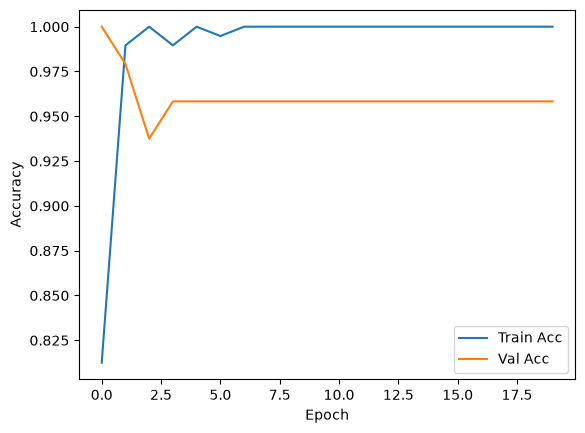

In [ ]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


Berdasarkan hasil training, model menunjukkan kenaikan akurasi yang sangat cepat hingga mencapai 1.0 pada data training. Namun, validation accuracy sedikit menurun menjadi sekitar 0.96 dan validation loss justru meningkat pada epoch akhir. Hal ini mengindikasikan adanya overfitting. Kondisi ini cukup wajar karena jumlah fitur HOG yang digunakan sangat besar, sekitar 34 ribu fitur, sedangkan data training hanya 192 sampel.

Meskipun demikian, model masih memperoleh akurasi test sebesar 0.88. Kesalahan prediksi lebih banyak terjadi pada kelas malam (13 dari 80 sampel) dibandingkan kelas siang (6 dari 80 sampel). Artinya, model masih cukup baik dalam membedakan kedua kelas, tetapi pengenalan gambar pada kondisi malam masih perlu ditingkatkan

## Simpan model


In [ ]:
model.save('day_night_classifier_model.h5')
